# **VoxCity Demo**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/kunifujiwara/VoxCity/blob/main/docs/examples/demo_quickstart.ipynb)

Build a 3D city from open map data, then simulate sunlight and views. No Python, no account.

Run the cells in order: click ▶, or press **Shift + Enter**. Choose **2.1** or **2.2**, not both.

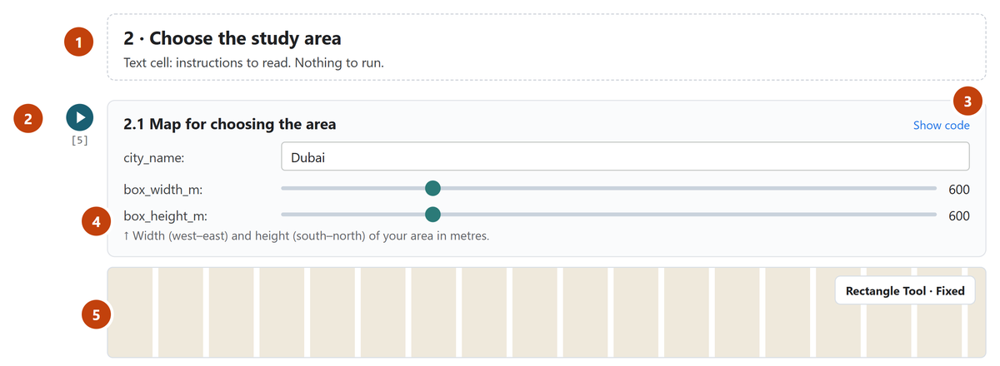

## 1 · Set-up

In [1]:
#@title 1.1 Install VoxCity (1–2 minutes) { display-mode: "form" }
!pip install -q voxcity

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done


## 2 · Choose the area
Run **2.1**. On the map: click **Fixed**, then click the centre of your street.

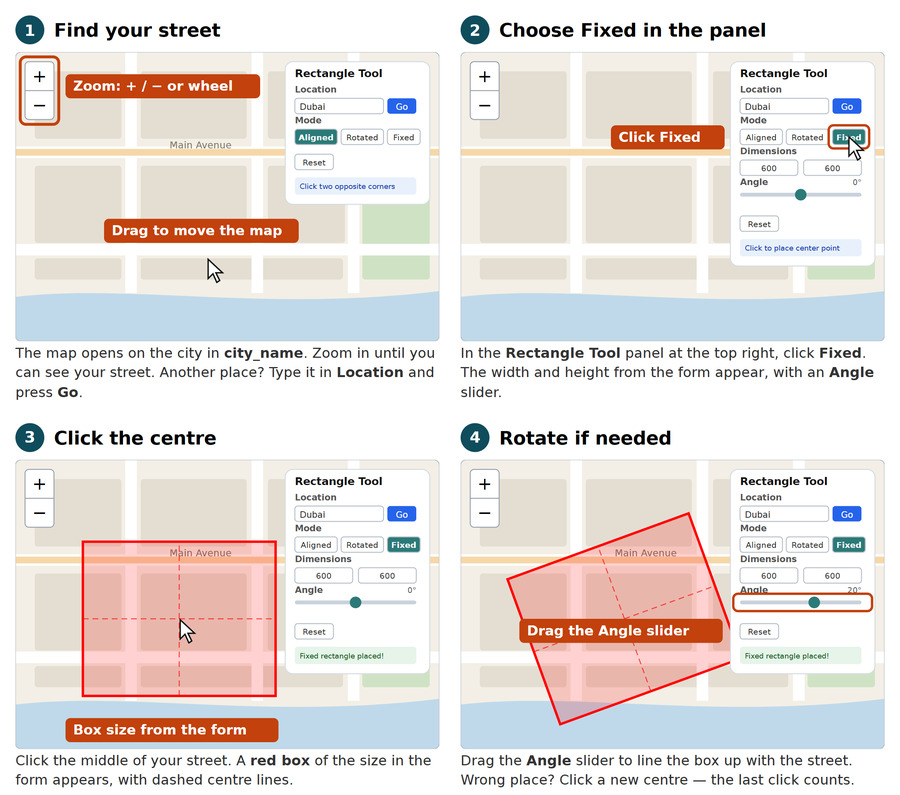

In [6]:
#@title 2.1 Map for choosing the area { display-mode: "form" }
city_name = "Lahore"  #@param {type:"string"}
box_width_m = 500  #@param {type:"slider", min:200, max:1500, step:50}
box_height_m = 500  #@param {type:"slider", min:200, max:1500, step:50}
from voxcity.geoprocessor.draw import create_rectangle_map
ui, rectangle_vertices = create_rectangle_map(city_name, zoom=15, width=box_width_m, height=box_height_m)
ui

In [3]:
#@title 2.2 (Alternative) Type the corners of the area { display-mode: "form" }
#@markdown Only if the map does not work. Longitude and latitude of the south-west and north-east corners.
west = -74.0160  #@param {type:"number"}
south = 40.7033  #@param {type:"number"}
east = -74.0100  #@param {type:"number"}
north = 40.7078  #@param {type:"number"}
rectangle_vertices = [(west, south), (west, north), (east, north), (east, south)]

## 3 · Build the 3D city

In [ ]:
#@title 3.1 Build the 3D city (1–5 minutes) { display-mode: "form" }
cube_size_m = 5  #@param {type:"slider", min:2, max:10, step:1}
from voxcity.generator import get_voxcity
voxcity = get_voxcity(rectangle_vertices, cube_size_m)

INFO | voxcity.voxcity.generator.api | Auto-selecting data sources for: building_source, land_cover_source, canopy_height_source, dem_source, building_complementary_source
INFO | voxcity.voxcity.generator.api | Detected country for ROI center (74.4105, 31.4698): Pakistan
INFO | voxcity.voxcity.generator.api | Selected data sources:
INFO | voxcity.voxcity.generator.api | - Buildings(base)=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Buildings(comp)=Microsoft Building Footprints | https://github.com/microsoft/GlobalMLBuildingFootprints
INFO | voxcity.voxcity.generator.api | - LandCover=OpenStreetMap | https://www.openstreetmap.org
INFO | voxcity.voxcity.generator.api | - Canopy=High Resolution 1m Global Canopy Height Maps v2 | https://registry.opendata.aws/dataforgood-fb-forestsv2/
INFO | voxcity.voxcity.generator.api | - DEM=FABDEM | https://doi.org/10.5523/bris.s5hqmjcdj8yo2ibzi9b4ew3sn
INFO | voxcity.voxcity.generator.api | - ComplementHeight=


  • Land Cover:  OpenStreetMap
  • Building:    OpenStreetMap
  • Canopy:      High Resolution 1m Global Canopy Height Maps v2
  • DEM:         FABDEM
------------------------------------------------------------
Downloading... (this may take a moment)
Fetching data from Overpass API...
  ✓ Dem complete (1/4)
  ✓ Canopy complete (2/4)


INFO | voxcity.voxcity.downloader.osm | Overpass attempt failed: timeout after 60s from https://overpass.kumi.systems/api/interpreter
INFO | voxcity.voxcity.downloader.osm | Overpass attempt failed: timeout after 60s from https://overpass.kumi.systems/api/interpreter
INFO | voxcity.voxcity.downloader.osm | Overpass endpoint unreachable, marking dead for this call: https://overpass.openstreetmap.ru/api/interpreter (HTTPSConnectionPool(host='overpass.openstreetmap.ru', port=443): Max retries exceeded with url: /api/interpreter?data=%0A++++%5Bout%3Ajson%5D%3B%0A++++%28%0A++++++way%5B%22building%22%5D%2831.465456649293518%2C74.40472883479991%2C31.474131764669288%2C74.41635754791264%29%3B%0A++++++way%5B%22building%3Apart%22%5D%2831.465456649293518%2C74.40472883479991%2C31.474131764669288%2C74.41635754791264%29%3B%0A++++++relation%5B%22building%22%5D%2831.465456649293518%2C74.40472883479991%2C31.474131764669288%2C74.41635754791264%29%3B%0A++++++way%5B%22tourism%22%3D%22artwork%22%5D%5B%22are

## 4 · Look at your city

In [8]:
#@title 4.1 3D view { display-mode: "form" }
from voxcity.visualizer import visualize_voxcity
visualize_voxcity(voxcity, mode="interactive", downsample=1)

## 5 · Simulations

In [ ]:
#@title 5.1 Sunlight at street level { display-mode: "form" }
#@markdown Uses typical weather of the nearest station (an average year), so there is no year to choose.
month = "June"  #@param ["January", "February", "March", "April", "May", "June", "July", "August", "September", "October", "November", "December"]
day = 21  #@param {type:"slider", min:1, max:31, step:1}
hour = 15  #@param {type:"slider", min:6, max:19, step:1}
import calendar
m = list(calendar.month_name).index(month)
d = min(day, calendar.monthrange(2025, m)[1])   # e.g. 31 June -> 30 June
from voxcity.simulator.solar import get_global_solar_irradiance_using_epw
solar_grid = get_global_solar_irradiance_using_epw(
    voxcity,
    calc_type="instantaneous",
    calc_time=f"{m:02d}-{d:02d} {hour:02d}:00:00",   # "MM-DD HH:MM:SS"
    download_nearest_epw=True,
    view_point_height=1.5,
    colormap="magma",
)

In [ ]:
#@title 5.2 Sky view or green view index { display-mode: "form" }
what = "Sky"  #@param ["Sky", "Greenery"]
from voxcity.simulator.visibility import get_view_index
if what == "Sky":
    view_grid = get_view_index(voxcity, mode="sky", view_point_height=1.5, colormap="BuPu_r", elevation_min_degrees=0)
else:
    view_grid = get_view_index(voxcity, mode="green", view_point_height=1.5, colormap="viridis")

## 6 · Export
OBJ: Blender, Rhino, Twinmotion · INX: ENVI-met · VOX: MagicaVoxel

In [ ]:
#@title 6.1 OBJ file { display-mode: "form" }
from voxcity.exporter.obj import export_obj
export_obj(voxcity, "output/obj", "voxcity")

In [ ]:
#@title 6.2 INX file for ENVI-met { display-mode: "form" }
from voxcity.exporter.envimet import export_inx
export_inx(voxcity, "output/envimet", "voxcity")

In [ ]:
#@title 6.3 VOX file for MagicaVoxel { display-mode: "form" }
from voxcity.exporter.magicavoxel import export_magicavoxel_vox
export_magicavoxel_vox(voxcity, "output/magicavoxel")

In [ ]:
#@title 6.4 Download everything as one zip file { display-mode: "form" }
import shutil
from google.colab import files
files.download(shutil.make_archive("voxcity_output", "zip", "output"))

## Next steps
[More tutorials](index.md) · [Questions](https://github.com/kunifujiwara/VoxCity/discussions) · [Cite the paper](https://doi.org/10.1016/j.compenvurbsys.2025.102366)